# 01 · Data Collection & Exploration
**Nhóm:** Trần Nhật Dương · Nguyễn Mạnh Hà · Hoàng Công Lý

Phần Collection của Dương được giữ nguyên bên dưới. Phần EDA của Hà là
**bản nháp có AI hỗ trợ**, số liệu sinh từ CSV thật; xem `../LLM_USAGE.md`.
Chưa xác nhận Hà tự thực hiện/diễn giải hoặc giảng viên duyệt dữ liệu.

## 1. Data Collection *(Owner: Trần Nhật Dương)*

### 1.1 Nguồn dữ liệu, tác giả & giấy phép
- **Tên bộ dữ liệu:** *In-Vehicle Coupon Recommendation* — UCI Machine Learning Repository, Dataset ID **603**.
- **Liên kết & DOI:** <https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation> · DOI: `10.24432/C5GS4P`.
- **Giấy phép (License):** **Creative Commons Attribution 4.0 International (CC BY 4.0)** — cho phép sử dụng, chia sẻ và phân tích học thuật với điều kiện ghi nhận nguồn tác giả.
- **Bài báo gốc:** Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., & MacNeille, P. (2017). *A Bayesian framework for learning rule sets for interpretable classification*. *Journal of Machine Learning Research (JMLR)*, 18(70), 1–37 (2357–2393).

### 1.2 Phương thức thu thập & ý nghĩa một dòng dữ liệu
- **Phương thức khảo sát:** Dữ liệu được thu thập thông qua khảo sát trực tuyến trên nền tảng **Amazon Mechanical Turk (MTurk)**.
- **Ý nghĩa mỗi quan sát (1 dòng):** Mỗi dòng (`12.684` dòng × `26` cột gồm `25` đặc trưng và `1` nhãn mục tiêu `Y`) mô tả **một kịch bản lái xe giả định** (điểm đến, thời tiết, nhiệt độ, thời điểm trong ngày, người đi cùng, loại coupon, thời hạn, khoảng cách/hướng đi ước lượng, kèm thông tin nhân khẩu học và thói quen tự khai báo) cùng câu trả lời nhị phân `Y` (`1` = đồng ý nhận coupon, `0` = từ chối).
- **Phân biệt ý định và hành vi thực tế:** `Y=1` phản ánh **ý định chấp nhận trong tình huống giả định**, không phải giao dịch đổi coupon thành công ngoài đời thực.

### 1.3 Lý do chọn dữ liệu & các giới hạn/bias cần lưu ý
- **Lý do lựa chọn:** Đủ quy mô (`12.684` dòng ≥ `3.000`, `25` features ≥ `10`), sạch cấu trúc, có giấy phép CC BY 4.0 rõ ràng, và giàu ngữ cảnh hành trình — phù hợp để khai thác sâu cả phân tích thống kê có kiểm soát nhiễu (Q1–Q5) lẫn bài toán phân loại nhị phân (Q6).
- **Giới hạn & nguy cơ bias:**
  1. **Thiếu `participant_id`:** Nhiều kịch bản có thể do cùng một người tham gia khảo sát trả lời lặp lại, nhưng file công bố không cung cấp mã định danh cá nhân (ảnh hưởng đến giả định độc lập khi tính CI và chiến lược chia train/test ở Q6).
  2. **Sai lệch chọn mẫu MTurk & tự khai báo:** Người trả lời trên MTurk không đại diện hoàn toàn cho mọi nhóm tài xế; tần suất ghé quán (`Bar`, `CoffeeHouse`, ...) là dữ liệu tự nhớ lại.
  3. **Ràng buộc thiết kế kịch bản:** Một số tổ hợp đặc trưng không độc lập (ví dụ `time = 7AM` gắn liền với `destination = Work`; `No Urgent Place` không có `direction_same = 1` hay `>=25 min`), đòi hỏi phân tầng kiểm soát confounder thay vì gộp thô.
  4. **Không suy diễn nhân quả:** Dữ liệu khảo sát quan sát chỉ cho phép kết luận **mối liên hệ**, không chứng minh tác động nhân quả.

### 1.4 Đối chiếu các phân tích công khai (`docs/related_work.md`)
- Nhóm đã rà soát bài báo gốc (Wang et al., 2017) cùng các repo tham khảo công khai như `seetharamanr86/customer_coupon_acceptance` và `arnavkundu/MLEngineerNanoDegree-Capstone`. Điểm khác biệt của nhóm là kết hợp kiểm soát confounder có hệ thống (D4), khoảng tin cậy bootstrap 95% (D5), kiểm tra độ bền (D6) và pipeline ML chống data leakage (chi tiết xem [`docs/related_work.md`](../docs/related_work.md)).

## 2. Overview và hợp đồng dữ liệu — Hà
Một dòng là một câu trả lời về **một kịch bản lái xe giả định**; không biết
mỗi người có bao nhiêu dòng. Không coi `Y=1` là giao dịch đã đổi coupon.
Chỉ đọc raw, giữ tên cột `passanger`; không ép `age/income` thành số liên tục.
Quy ước được chốt trong `../docs/ha_analysis_protocol.md` trước Q3/Q4.

In [1]:
import hashlib
from importlib.metadata import version
from pathlib import Path
import platform
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/coupon_project").is_dir(), "Start in repo root or notebooks/"
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coupon_project.analysis import (
    COUPON_FREQUENCY,
    DESTINATIONS,
    MIN_N,
    N_BOOT,
    PASSENGERS,
    SEED,
    audit_row,
    matched_frequency,
    rate_table,
    save_figure,
    save_table,
)
from coupon_project.data_io import load_raw_data
from coupon_project.quality import missing_table, target_is_binary

plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 20)

raw_path = ROOT / "data/raw/in-vehicle-coupon-recommendation.csv"
df = load_raw_data(raw_path)
assert target_is_binary(df)

raw_sha = hashlib.sha256(raw_path.read_bytes()).hexdigest()
audit = []

print(f"Raw: {df.shape[0]:,} rows x {df.shape[1]} columns; SHA-256: {raw_sha}")
print(f"MIN_N={MIN_N}; bootstrap={N_BOOT:,}; seed={SEED}; rates in [0,1], differences in pp")

Raw: 12,684 rows x 26 columns; SHA-256: d47897367f5a12a31dece0f4e42d7bd9da76d7016b568da511b50335d08dcb43
MIN_N=30; bootstrap=10,000; seed=17104; rates in [0,1], differences in pp


In [2]:
display(df.head())

binary_cols = [
    "has_children",
    "toCoupon_GEQ5min",
    "toCoupon_GEQ15min",
    "toCoupon_GEQ25min",
    "direction_same",
    "direction_opp",
    "Y",
]
ordered_cols = ["age", "income"] + list(COUPON_FREQUENCY.values())


def classify_column(col_name: str) -> str:
    if col_name in binary_cols:
        return "binary"
    if col_name == "temperature":
        return "discrete scenario temperature"
    if col_name in ordered_cols:
        return "ordered category (not exact numeric)"
    return "nominal category"


schema = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "n_unique": df.nunique(dropna=True).values,
    "missing": df.isna().sum().values,
})
schema["semantic_type"] = schema["column"].map(classify_column)
display(schema)
save_table(schema, ROOT, "eda_schema")

target = rate_table(df.assign(sample="all"), ["sample"])
display(target)
save_table(target, ROOT, "eda_target")

duplicate_extra = int(df.duplicated().sum())
duplicate_all = int(df.duplicated(keep=False).sum())
print(f"Exact duplicate extra rows: {duplicate_extra}; all rows in duplicate sets: {duplicate_all}")

audit.append(
    audit_row(
        "load and retain raw rows",
        len(df),
        len(df),
        "No participant ID; identical rows are not automatically errors",
    )
)

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


,column,dtype,n_unique,missing,semantic_type
0,destination,str,3,0,nominal category
1,passanger,str,4,0,nominal category
2,weather,str,3,0,nominal category
3,temperature,int64,3,0,discrete scenario temperature
4,time,str,5,0,nominal category
5,coupon,str,5,0,nominal category
6,expiration,str,2,0,nominal category
7,gender,str,2,0,nominal category
8,age,str,8,0,ordered category (not exact numeric)
9,maritalStatus,str,5,0,nominal category


,sample,n,accepted,rate,ci_low,ci_high,small_n
0,all,12684,7210,0.568433,0.559794,0.57703,False


Exact duplicate extra rows: 74; all rows in duplicate sets: 148


## 3. Missingness và nhãn
NaN khác `never`. Audit mọi cột, đồng thời kiểm tra thiếu thói quen phù hợp
theo coupon. Không loại dòng vì thiếu một cột không dùng cho câu hỏi.

,column,missing_count,missing_pct
0,car,12576,99.15
1,CoffeeHouse,217,1.71
2,Restaurant20To50,189,1.49
3,CarryAway,151,1.19
4,RestaurantLessThan20,130,1.02
5,Bar,107,0.84
6,weather,0,0.00
7,temperature,0,0.00
8,destination,0,0.00
9,passanger,0,0.00


,n,matched_missing,matched_missing_pct
coupon,,,
Bar,2017,21,1.041150
Carry out & Take away,2393,22,0.919348
Coffee House,3996,72,1.801802
Restaurant(20-50),1492,22,1.474531
Restaurant(<20),2786,27,0.969131


,n
number_missing_habits,
0,12079
1,542
2,21
5,42


Whitespace/case collision candidates: []


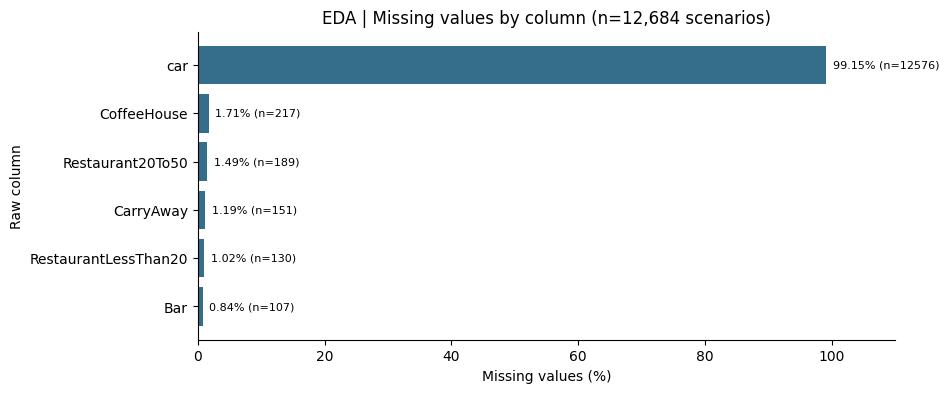

In [3]:
missing = missing_table(df).reset_index(names="column")
display(missing)
save_table(missing, ROOT, "eda_missing")

matched = matched_frequency(df)
missing_by_coupon = (
    df.assign(matched_missing=matched.isna().astype(int))
    .groupby("coupon")
    .agg(n=("Y", "size"), matched_missing=("matched_missing", "sum"))
)
missing_by_coupon["matched_missing_pct"] = 100 * missing_by_coupon["matched_missing"] / missing_by_coupon["n"]
display(missing_by_coupon)
save_table(missing_by_coupon.reset_index(), ROOT, "eda_matched_missing")

pattern = df[list(COUPON_FREQUENCY.values())].isna().sum(axis=1).value_counts().sort_index()
display(pattern.rename_axis("number_missing_habits").to_frame("n"))
save_table(pattern.rename_axis("number_missing_habits").reset_index(name="n"), ROOT, "eda_missing_patterns")

domain_rows = []
label_issues = []
for column in df.columns:
    for value, n in df[column].value_counts(dropna=False).items():
        domain_rows.append({
            "column": column,
            "value": "<NA>" if pd.isna(value) else str(value),
            "n": n,
            "pct": n / len(df) * 100,
        })
    if df[column].dtype == "object":
        values = pd.Series(df[column].dropna().unique(), dtype="string")
        normalized = values.str.strip().str.casefold()
        has_issue = normalized.duplicated(keep=False) | values.ne(values.str.strip())
        for value in values[has_issue]:
            label_issues.append({"column": column, "value": value})

domains = pd.DataFrame(domain_rows)
save_table(domains, ROOT, "eda_domains")
print("Whitespace/case collision candidates:", label_issues)
save_table(pd.DataFrame(label_issues, columns=["column", "value"]), ROOT, "eda_label_issues")

fig, ax = plt.subplots(figsize=(9, 4))
shown = missing.loc[missing["missing_count"] > 0]
ax.barh(shown["column"], shown["missing_pct"], color="#346e8b")
ax.invert_yaxis()
ax.set(
    xlabel="Missing values (%)",
    ylabel="Raw column",
    xlim=(0, 110),
    title=f"EDA | Missing values by column (n={len(df):,} scenarios)",
)
for i, row in enumerate(shown.itertuples()):
    ax.text(row.missing_pct + 1, i, f"{row.missing_pct:.2f}% (n={row.missing_count})", va="center", fontsize=8)

save_figure(fig, ROOT, "eda_missing")
plt.show()

## 4. Phân phối, giá trị bất hợp lý và cờ logic
Các cột số là cờ nhị phân và nhiệt độ theo kịch bản rời rạc. Kiểm tra miền
hợp lệ thay vì dùng z-score/IQR để xóa các mức hợp lệ. Các nhóm tuổi/thu
nhập chỉ có thứ tự, không có giá trị chính xác để tính trung bình trực tiếp.

,check,violations
0,has_children outside 0/1 or missing,0
1,toCoupon_GEQ5min outside 0/1 or missing,0
2,toCoupon_GEQ15min outside 0/1 or missing,0
3,toCoupon_GEQ25min outside 0/1 or missing,0
4,direction_same outside 0/1 or missing,0
5,direction_opp outside 0/1 or missing,0
6,Y outside 0/1 or missing,0
7,temperature outside observed scenario domain 3...,0
8,GEQ25=1 but GEQ15=0,0
9,GEQ15=1 but GEQ5=0,0


Constant columns: ['toCoupon_GEQ5min']

age


,n
age,
21,2653
26,2559
31,2039
50plus,1788
36,1319
41,1093
46,686
below21,547



income


,n
income,
$25000 - $37499,2013
$12500 - $24999,1831
$37500 - $49999,1805
$100000 or More,1736
$50000 - $62499,1659
Less than $12500,1042
$87500 - $99999,895
$75000 - $87499,857
$62500 - $74999,846



temperature


... (3 outputs left out)


passanger


,n
passanger,
Alone,7305
Friend(s),3298
Partner,1075
Kid(s),1006



coupon


,n
coupon,
Coffee House,3996
Restaurant(<20),2786
Carry out & Take away,2393
Bar,2017
Restaurant(20-50),1492


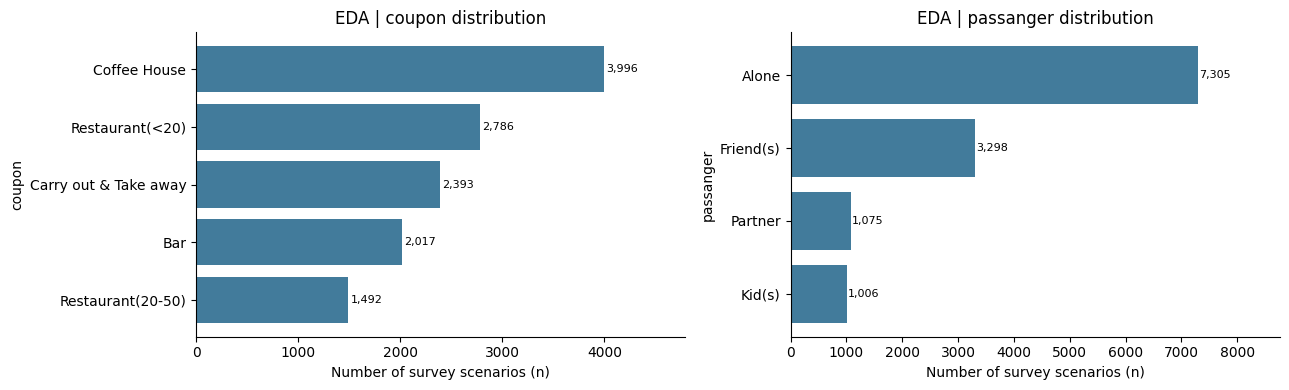

In [4]:
checks = []
for column in binary_cols:
    violations = int((~df[column].isin([0, 1])).sum())
    checks.append({"check": f"{column} outside 0/1 or missing", "violations": violations})

checks.extend([
    {
        "check": "temperature outside observed scenario domain 30/55/80",
        "violations": int((~df["temperature"].isin([30, 55, 80])).sum()),
    },
    {
        "check": "GEQ25=1 but GEQ15=0",
        "violations": int(((df["toCoupon_GEQ25min"] == 1) & (df["toCoupon_GEQ15min"] == 0)).sum()),
    },
    {
        "check": "GEQ15=1 but GEQ5=0",
        "violations": int(((df["toCoupon_GEQ15min"] == 1) & (df["toCoupon_GEQ5min"] == 0)).sum()),
    },
    {
        "check": "direction_same + direction_opp != 1",
        "violations": int(((df["direction_same"] + df["direction_opp"]) != 1).sum()),
    },
])
checks = pd.DataFrame(checks)
display(checks)
save_table(checks, ROOT, "eda_logic_checks")
assert checks["violations"].sum() == 0, "Inspect invalid rows before proceeding"

print("Constant columns:", schema.loc[schema["n_unique"].eq(1), "column"].tolist())
for column in ["age", "income", "temperature", "time", "passanger", "coupon"]:
    print(f"\n{column}")
    display(df[column].value_counts(dropna=False).to_frame("n"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column in zip(axes, ["coupon", "passanger"]):
    counts = df[column].value_counts()
    ax.barh(counts.index, counts.values, color="#427b9b")
    ax.invert_yaxis()
    ax.set(
        xlabel="Number of survey scenarios (n)",
        ylabel=column,
        title=f"EDA | {column} distribution",
    )
    ax.margins(x=0.2)
    for i, n_val in enumerate(counts.values):
        ax.text(n_val + 20, i, f"{n_val:,}", va="center", fontsize=8)

fig.tight_layout()
save_figure(fig, ROOT, "eda_distributions")
plt.show()

## 5. Quan hệ biến và hỗ trợ cho Q3/Q4
Chỉ audit chất lượng và số mẫu; các so sánh sâu thuộc notebook Q3/Q4.
Bảng chéo có ô 0 là **không có tình huống khảo sát**, không phải tỷ lệ nhận 0%.

In [5]:
for column in ["coupon", "expiration", "destination", "passanger"]:
    table = rate_table(df, [column])
    display(table)
    save_table(table, ROOT, "eda_by_" + column)

support = pd.crosstab(df["passanger"], df["destination"]).reindex(
    index=PASSENGERS,
    columns=DESTINATIONS,
    fill_value=0,
)
display(support)
save_table(support.reset_index(), ROOT, "eda_passanger_destination_n")

distance_support = pd.crosstab(df["toCoupon_GEQ15min"], df["toCoupon_GEQ25min"])
display(distance_support)
save_table(distance_support.reset_index(), ROOT, "eda_distance_flags_n")

print("Y counts:", df["Y"].value_counts().to_dict())

,coupon,n,accepted,rate,ci_low,ci_high,small_n
0,Bar,2017,827,0.410015,0.388741,0.431630,False
1,Carry out & Take away,2393,1760,0.735478,0.717439,0.752763,False
2,Coffee House,3996,1995,0.499249,0.483755,0.514745,False
3,Restaurant(20-50),1492,658,0.441019,0.416009,0.466332,False
4,Restaurant(<20),2786,1970,0.707107,0.689932,0.723711,False


,expiration,n,accepted,rate,ci_low,ci_high,small_n
0,1d,7091,4436,0.625582,0.614252,0.636775,False
1,2h,5593,2774,0.495977,0.482881,0.509079,False


,destination,n,accepted,rate,ci_low,ci_high,small_n
0,Home,3237,1639,0.506333,0.489113,0.523538,False
1,No Urgent Place,6283,3982,0.633774,0.621783,0.645601,False
2,Work,3164,1589,0.502212,0.484798,0.519621,False


,passanger,n,accepted,rate,ci_low,ci_high,small_n
0,Alone,7305,3841,0.525804,0.514343,0.537238,False
1,Friend(s),3298,2221,0.673438,0.657240,0.689234,False
2,Kid(s),1006,508,0.504970,0.474114,0.535788,False
3,Partner,1075,640,0.595349,0.565719,0.624300,False


destination,No Urgent Place,Home,Work
passanger,,,
Alone,1299,2842,3164
Friend(s),3298,0,0
Partner,816,259,0
Kid(s),870,136,0


toCoupon_GEQ25min,0,1
toCoupon_GEQ15min,,
0,5562,0
1,5611,1511


Y counts: {1: 7210, 0: 5474}


## 6. Cleaning plan — quyết định rõ trước khi tạo processed
- Tất cả cột raw được giữ: không có căn cứ xóa dòng chỉ vì `car` thiếu.
- `car`: giữ cho audit; không dùng trong Q3/Q4 vì không thuộc câu hỏi và thiếu nhiều.
- Năm thói quen: giữ NaN; Q3 lọc thiếu **đúng cột được mapping** ở contrast chính.
- `age/income/time`: giữ nhãn; nhiệt độ giữ miền rời rạc; không ép số hoặc dựng ngày.
- Các cờ: kiểm tra logic, giữ tên và giá trị; cột hằng không dùng làm bằng chứng phân biệt.
- Duplicates: giữ ở chính, Q3 chạy thêm sensitivity; không có ID để xác định bản ghi lỗi.
- Không có nhãn cần sửa theo kiểm tra whitespace/case; nếu nguồn thay đổi, phải audit lại.
- Processed chỉ thêm biến mô tả, không fit imputer/encoder; ML vẫn phải xử lý trong Pipeline train.

In [6]:
processed = df.copy()
processed["matched_frequency"] = matched
processed["frequent_user"] = pd.Series(pd.NA, index=df.index, dtype="Int64")

known = matched.notna()
processed.loc[known, "frequent_user"] = matched.loc[known].isin(["1~3", "4~8", "gt8"]).astype(int)

audit.append(
    audit_row(
        "add matched_frequency and nullable frequent_user",
        len(df),
        len(processed),
        "Derived columns only; raw values, missing values, duplicates retained",
    )
)

processed_path = ROOT / "data/processed/ha_analysis_ready.csv"
processed_path.parent.mkdir(parents=True, exist_ok=True)
processed.to_csv(processed_path, index=False)
pd.testing.assert_frame_equal(processed[df.columns], df)

audit_df = pd.DataFrame(audit)
display(audit_df)
save_table(audit_df, ROOT, "eda_row_audit")
print("Saved:", processed_path.relative_to(ROOT))

,action,n_before,n_after,rows_removed,reason
0,load and retain raw rows,12684,12684,0,No participant ID; identical rows are not auto...
1,add matched_frequency and nullable frequent_user,12684,12684,0,"Derived columns only; raw values, missing valu..."


Saved: data\processed\ha_analysis_ready.csv


## 7. Năm quan sát EDA — bản nháp số liệu tự sinh
Các dòng dưới lấy trực tiếp từ output. Hà cần tự kiểm chứng và tự trình bày
nhận xét; chưa phải reflection hay kết luận do Hà viết.

In [7]:
import json

y = target.iloc[0]
car_pct = float(missing.set_index("column").loc["car", "missing_pct"])
const_cols = ", ".join(schema.loc[schema["n_unique"].eq(1), "column"])

observations = [
    (
        f"1. Có {len(df):,} dòng, {df.shape[1]} cột; Y=1 có {int(y.accepted):,}/{int(y.n):,} "
        f"({y.rate * 100:.2f}%; Wilson 95% CI [{y.ci_low * 100:.2f}, {y.ci_high * 100:.2f}]%). "
        "Đây là ý định trong khảo sát."
    ),
    (
        f"2. car thiếu {df['car'].isna().sum():,} dòng ({car_pct:.2f}%); "
        f"thói quen phù hợp thiếu {matched.isna().sum():,} dòng ({matched.isna().mean() * 100:.2f}%). "
        "Không dropna toàn bảng."
    ),
    (
        f"3. Có {duplicate_extra} dòng trùng thêm ({duplicate_extra / len(df) * 100:.2f}%); "
        "chưa có căn cứ xác định đó là lỗi. Phân tích chính giữ nguyên, kiểm tra độ bền riêng."
    ),
    (
        f"4. Cột hằng: {const_cols}. Có {int(checks['violations'].sum())} vi phạm "
        "trong các kiểm tra miền/cờ đã liệt kê; không đồng nghĩa dữ liệu không còn bias."
    ),
    (
        f"5. Friend(s): No Urgent Place n={int(support.loc['Friend(s)', 'No Urgent Place'])}, "
        f"Home n={int(support.loc['Friend(s)', 'Home'])}, "
        f"Work n={int(support.loc['Friend(s)', 'Work'])}. "
        "Q4 phải giới hạn so sánh theo common support, không diễn giải crude là tác động của bạn bè."
    ),
]
display(Markdown("\n\n".join(observations)))

(ROOT / "reports/ha_eda_observations.md").write_text(
    "# EDA của Hà — bản nháp AI hỗ trợ\n\n"
    + "\n\n".join(observations)
    + "\n\nNguồn: UCI #603, DOI 10.24432/C5GS4P, CC BY 4.0. Xem ha_eda_*.csv và notebook 01.\n",
    encoding="utf-8",
)

metadata = {
    "raw_sha256": raw_sha,
    "rows": len(df),
    "columns": len(df.columns),
    "python": platform.python_version(),
    "packages": {pkg: version(pkg) for pkg in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]},
    "source": "https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation",
    "license": "CC BY 4.0",
    "min_n": MIN_N,
    "bootstrap_replicates": N_BOOT,
    "seed": SEED,
    "status": "AI-assisted draft; human verification not asserted",
}
(ROOT / "reports/ha_run_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_sha

1. Có 12,684 dòng, 26 cột; Y=1 có 7,210/12,684 (56.84%; Wilson 95% CI [55.98, 57.70]%). Đây là ý định trong khảo sát.

2. car thiếu 12,576 dòng (99.15%); thói quen phù hợp thiếu 164 dòng (1.29%). Không dropna toàn bảng.

3. Có 74 dòng trùng thêm (0.58%); chưa có căn cứ xác định đó là lỗi. Phân tích chính giữ nguyên, kiểm tra độ bền riêng.

4. Cột hằng: toCoupon_GEQ5min. Có 0 vi phạm trong các kiểm tra miền/cờ đã liệt kê; không đồng nghĩa dữ liệu không còn bias.

5. Friend(s): No Urgent Place n=3298, Home n=0, Work n=0. Q4 phải giới hạn so sánh theo common support, không diễn giải crude là tác động của bạn bè.